# Copper price forecasting: Replication of results from Liu (2017) and + Díaz et al.

This notebook has **three separate experiments**:

1. **Liu et al. (2017)-style replication attempt** on the paper's 2008–2015 sample, using the eight price series, a decision tree, the paper's lag parameter `D`, forecast-distance parameter `G`, and rolling-origin forecasts. It creates a Figure 8-style panel plot for `D=10` and `G = 0, 5, 30, 120, 180, 360, 720, 1080`.

2. **Diaz et al. (2017)-style replication attempt** on the paper's 2008–2015 sample and 2008-2020 sample, using the same eight price series as Liu, a regression tree, a random forest, a gradient boosting regression tree, and a random walk model. The paper uses the same lag parameter `D`, forecast-distance parameter `G`, and rolling-origin forecasts. It creates a Figure 8-style panel plot for `D=10` and `G = 0, 5, 30, 120, 180, 360, 720, 1080`.

3. **Modern model comparison** on the available 2008–2026 data, comparing regression tree, random forest, gradient boosting, optional XGBoost, and a random-walk benchmark on a chronological held-out period.

**NOTE:** This is a *replication attempt* of these papers' results to see if these models will work on the provided data sets. The same-ish code will be applied to the lithium market, but with lithium centered data. In addition, machine learning will be applied to supply and demand data to develop a market balance prediction model. this will be used to help aid in lithium price predictions 

**ANOTHER NOTE:** I used ChatGPT to help generate the base code of this noetbook, but then further edited it to ensure it worked correctly and to add in analyis it failed to include


## 1. Imports and settings

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
BASE = Path.cwd()
OUT = BASE / "copper_forecasting_outputs"
OUT.mkdir(parents=True, exist_ok=True)

FILES = {
    "Copper": "Copper Futures Historical Data(2).csv",
    "Gold": "Gold Futures Historical Data(2).csv",
    "Silver": "Silver Futures Historical Data(2).csv",
    "Oil": "Crude Oil WTI Futures Historical Data(2).csv",
    "Gas": "Natural Gas Futures Historical Data(2).csv",
    "Lean Hogs": "Lean Hogs Futures Historical Data(2).csv",
    "Coffee": "US Coffee C Futures Historical Data(2).csv",
    "Dow Jones": "Dow Jones Industrial Average Historical Data(2).csv",
}

try:
    from xgboost import XGBRegressor
    HAS_XGBOOST = True
except ImportError:
    HAS_XGBOOST = False
    print("xgboost is not installed; XGBoost will be skipped without stopping the notebook.")

## 2. Load and clean the eight price series

In [2]:
frames = []
for variable, filename in FILES.items():
    path = BASE / filename
    if not path.exists():
        raise FileNotFoundError(
            f"Missing {filename}. Put all eight uploaded CSVs in the same folder as this notebook: {BASE}"
        )
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    # Investing.com sometimes formats prices with thousands separators.
    df["Price"] = pd.to_numeric(
        df["Price"].astype(str).str.replace(",", "", regex=False).str.replace("%", "", regex=False),
        errors="coerce"
    )
    df = df[["Date", "Price"]].dropna().drop_duplicates("Date")
    df = df.rename(columns={"Price": variable}).sort_values("Date")
    frames.append(df)

data = frames[0]
for frame in frames[1:]:
    data = data.merge(frame, on="Date", how="inner")
data = data.sort_values("Date").set_index("Date").sort_index()
variables = list(FILES.keys())
data = data[variables].replace([np.inf, -np.inf], np.nan).dropna()

print(f"Common-date observations: {len(data):,}")
print(f"Available date range: {data.index.min().date()} through {data.index.max().date()}")
display(data.head())
# Save the aligned data for reproducibility.
data.to_csv(OUT / "aligned_eight_series_data.csv")

Common-date observations: 3,973
Available date range: 2008-01-02 through 2025-10-30


,Copper,Gold,Silver,Oil,Gas,Lean Hogs,Coffee,Dow Jones
Date,,,,,,,,
2008-01-02,3.0640,860.0,15.290,99.62,7.850,57.17,134.00,13043.96
2008-01-03,3.1880,869.1,15.500,99.18,7.674,56.48,135.20,13056.72
2008-01-04,3.1575,865.7,15.462,97.91,7.841,56.40,132.70,12800.18
2008-01-07,3.1410,862.0,15.290,95.09,7.879,55.70,131.40,12827.49
2008-01-08,3.2985,880.3,15.815,96.33,7.967,55.88,135.45,12589.07


## 3. Descriptive statistics and price-series overview

,Mean,Std. Dev.,Min,Max
Copper,3.299,0.783,1.266,5.820
Gold,1528.300,535.667,705.000,4359.400
Silver,21.880,7.269,8.790,53.296
Oil,73.388,22.300,11.570,145.290
Gas,3.807,1.839,1.546,13.577
Lean Hogs,78.767,16.859,37.330,133.880
Coffee,165.894,61.979,86.650,432.350
Dow Jones,21521.602,10247.060,6547.050,47706.370


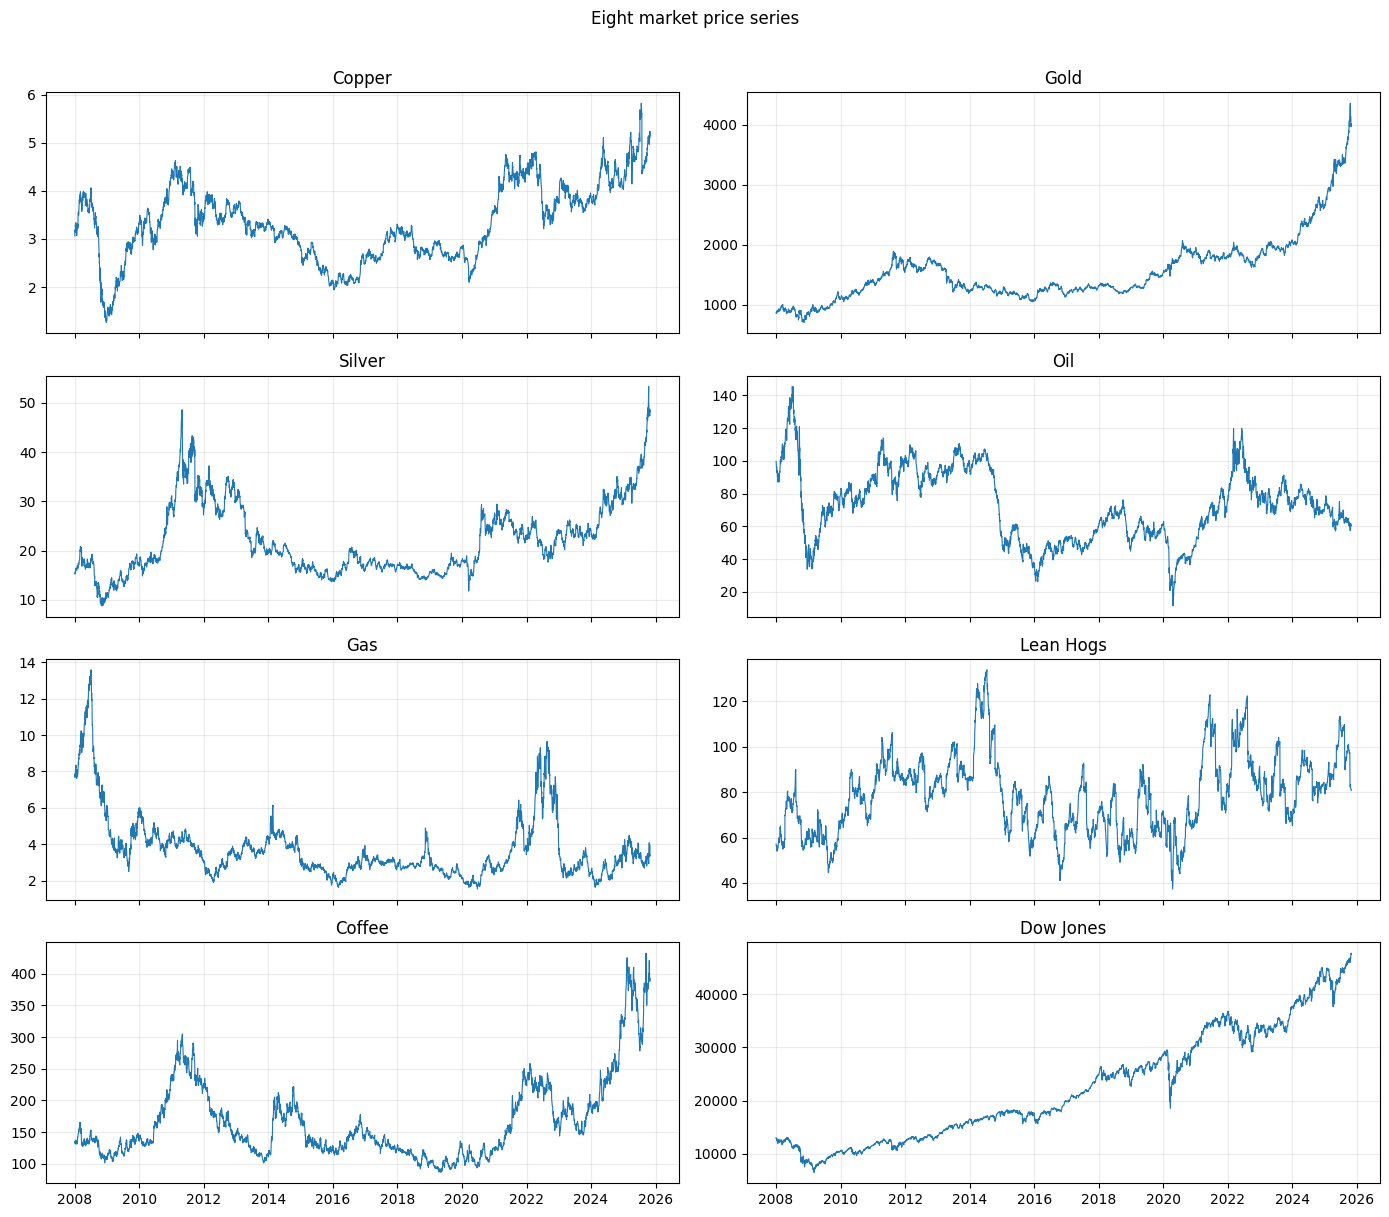

,Copper,Gold,Silver,Oil,Gas,Lean Hogs,Coffee,Dow Jones
Copper,1.000,0.693,0.771,0.544,0.170,0.550,0.720,0.514
Gold,0.693,1.000,0.739,-0.005,-0.257,0.376,0.743,0.792
Silver,0.771,0.739,1.000,0.367,-0.123,0.478,0.753,0.306
Oil,0.544,-0.005,0.367,1.000,0.578,0.525,0.288,-0.196
Gas,0.170,-0.257,-0.123,0.578,1.000,0.098,0.068,-0.232
Lean Hogs,0.550,0.376,0.478,0.525,0.098,1.000,0.479,0.235
Coffee,0.720,0.743,0.753,0.288,0.068,0.479,1.000,0.429
Dow Jones,0.514,0.792,0.306,-0.196,-0.232,0.235,0.429,1.000


In [3]:
stats = data.describe().T[["mean", "std", "min", "max"]].rename(
    columns={"mean":"Mean", "std":"Std. Dev.", "min":"Min", "max":"Max"}
).round(3)
display(stats)
stats.to_csv(OUT / "table_descriptive_statistics.csv")

fig, axes = plt.subplots(4, 2, figsize=(14, 12), sharex=True)
for ax, col in zip(axes.ravel(), variables):
    ax.plot(data.index, data[col], linewidth=0.8)
    ax.set_title(col)
    ax.grid(alpha=0.25)
fig.suptitle("Eight market price series", y=1.01)
fig.tight_layout()
fig.savefig(OUT / "figure1_eight_price_series.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

corr = data.corr()
display(corr.round(3))
corr.to_csv(OUT / "table_correlation_matrix.csv")

## 4. Liu et al. (2017): paper-period data and rolling-origin decision tree

The paper reports data from **January 3, 2008 through December 1, 2015**. We filter the common-date dataset to that period. For each forecast origin `t`, predictors contain the latest `D` observations of all eight variables, including the observation at `t`. Following the paper's described construction, historical training pairs map each feature window to copper's price on that historical day; the fitted tree is then applied at the forecast origin and its prediction is compared with copper `G+1` observations later. This is a **paper-inspired replication of the published procedure**, not a standard horizon-shifted supervised forecasting setup.

The paper's plot uses `D=10` and `G = 0, 5, 30, 120, 180, 360, 720, 1080`. For runtime, forecasts are generated every 30 observations by default; set `PLOT_EVERY = 1` for denser predictions. The paper's source data preprocessing and exact observations may differ from the newly downloaded CSVs, so exact numerical reproduction is not guaranteed.

In [4]:
PAPER_START = pd.Timestamp("2008-01-03")
PAPER_END = pd.Timestamp("2015-12-01")
paper_data = data.loc[PAPER_START:PAPER_END].copy()
D_PAPER = 10
G_VALUES = [0, 5, 30, 120, 180, 360, 720, 1080]
PLOT_EVERY = 30  # set to 1 for dense daily-origin predictions
MIN_TRAIN_ROWS = 100

print(f"Paper-period common-date observations: {len(paper_data):,}")
print(f"Paper-period dates available: {paper_data.index.min().date()} through {paper_data.index.max().date()}")
if len(paper_data) < 500:
    print("Warning: fewer observations than expected; check input CSV coverage.")
    
    


def build_paper_arrays(frame, D):
    """X_t contains the latest D observations; y_t is copper price on day t."""
    values = frame[variables].to_numpy(dtype=float)
    X, y, origins = [], [], []
    for t in range(D - 1, len(frame)):
        X.append(values[t-D+1:t+1, :].reshape(-1))
        y.append(values[t, variables.index("Copper")])
        origins.append(t)
    names = [f"{col}_lag{lag}" for lag in range(D-1, -1, -1) for col in variables]
    return np.asarray(X), np.asarray(y), np.asarray(origins), names

def rolling_tree_forecasts(frame, D, G, every=1, min_train_rows=100):
    """Paper-inspired rolling-origin procedure; compare forecast with copper at t+G+1."""
    X, y, origins, feature_names = build_paper_arrays(frame, D)
    n_frame = len(frame)
    origin_to_sample = {int(t): i for i, t in enumerate(origins)}
    # Only origins with an observed future actual are included in evaluation.
    selected_origins = origins[(origins + G + 1 < n_frame)][::every]
    records = []
    for t in selected_origins:
        # Historical training pairs have same-day labels and are known by origin t.
        train_ids = np.where(origins <= t)[0]
        if len(train_ids) < min_train_rows:
            continue
        sample_id = origin_to_sample[int(t)]
        model = DecisionTreeRegressor(random_state=RANDOM_STATE, max_depth=23)
        model.fit(X[train_ids], y[train_ids])
        pred = float(model.predict(X[[sample_id]])[0])
        target_pos = int(t + G + 1)
        records.append({
            "OriginDate": frame.index[int(t)], "TargetDate": frame.index[target_pos],
            "OriginPosition": int(t), "TargetPosition": target_pos, "G": int(G), "D": int(D),
            "Actual": float(frame["Copper"].iloc[target_pos]), "Prediction": pred,
            "TrainingRows": int(len(train_ids)),
        })
    return pd.DataFrame(records)

liu_forecasts = []
for G in G_VALUES:
    print(f"Generating Liu-style rolling forecasts: D={D_PAPER}, G={G} ...")
    result = rolling_tree_forecasts(paper_data, D_PAPER, G, every=PLOT_EVERY,
                                    min_train_rows=MIN_TRAIN_ROWS)
    print(f"  forecasts generated: {len(result)}")
    if not result.empty:
        liu_forecasts.append(result)
liu_forecasts = pd.concat(liu_forecasts, ignore_index=True) if liu_forecasts else pd.DataFrame()
liu_forecasts.to_csv(OUT / "liu2017_style_rolling_forecasts_D10.csv", index=False)
print(f"Saved {len(liu_forecasts):,} rolling-origin forecasts.")
if liu_forecasts.empty:
    raise ValueError("No Liu-style forecasts were generated. Check paper-period data coverage.")

Paper-period common-date observations: 1,951
Paper-period dates available: 2008-01-03 through 2015-12-01
Generating Liu-style rolling forecasts: D=10, G=0 ...
  forecasts generated: 61
Generating Liu-style rolling forecasts: D=10, G=5 ...
  forecasts generated: 61
Generating Liu-style rolling forecasts: D=10, G=30 ...
  forecasts generated: 60
Generating Liu-style rolling forecasts: D=10, G=120 ...
  forecasts generated: 57
Generating Liu-style rolling forecasts: D=10, G=180 ...
  forecasts generated: 55
Generating Liu-style rolling forecasts: D=10, G=360 ...
  forecasts generated: 49
Generating Liu-style rolling forecasts: D=10, G=720 ...
  forecasts generated: 37
Generating Liu-style rolling forecasts: D=10, G=1080 ...
  forecasts generated: 25
Saved 405 rolling-origin forecasts.


In [12]:

import pandas as pd
from pathlib import Path

# Folder containing the eight Investing.com CSV files
DATA_DIR = Path(".")
OUT = Path("liu_replication_outputs")
OUT.mkdir(parents=True, exist_ok=True)

# Liu et al. (2017) study period
START_DATE = "2008-01-03"
END_DATE = "2015-12-01"

# Create a date index containing weekdays only.
# Weekdays on which markets were closed will be interpolated.
weekday_dates = pd.bdate_range(
    start=START_DATE,
    end=END_DATE,
    name="Date"
)

# CSV filenames and corresponding variable names
files = {
    "Copper": "Copper Futures Historical Data(2).csv",
    "Gold": "Gold Futures Historical Data(2).csv",
    "Silver": "Silver Futures Historical Data(2).csv",
    "Crude_Oil": "Crude Oil WTI Futures Historical Data(2).csv",
    "Natural_Gas": "Natural Gas Futures Historical Data(2).csv",
    "Lean_Hogs": "Lean Hogs Futures Historical Data(2).csv",
    "Coffee": "US Coffee C Futures Historical Data(2).csv",
    "Dow_Jones": "Dow Jones Industrial Average Historical Data(2).csv",
}

processed_series = {}
audit_rows = []

for variable, filename in files.items():

    # Load raw market data
    df = pd.read_csv(DATA_DIR / filename)

    # Parse dates and convert prices to numeric values.
    # Removing commas is necessary for Dow Jones prices.
    df["Date"] = pd.to_datetime(
        df["Date"],
        format="%m/%d/%Y",
        errors="coerce"
    )

    df["Price"] = pd.to_numeric(
        df["Price"].astype(str).str.replace(",", "", regex=False),
        errors="coerce"
    )

    # Restrict the data to Liu et al.'s date range
    df = df.dropna(subset=["Date", "Price"])
    df = df.loc[df["Date"].between(START_DATE, END_DATE)]

    # One price per date, ordered chronologically
    prices = (
        df.groupby("Date")["Price"]
        .mean()
        .sort_index()
    )

    # Reindex to all weekdays, introducing NaN on missing weekdays
    prices_weekdays = prices.reindex(weekday_dates)

    missing_before = int(prices_weekdays.isna().sum())

    # Linear interpolation:
    # For a single missing weekday, this equals
    # (previous observed price + next observed price) / 2.
    # For consecutive missing weekdays, it interpolates between
    # the nearest available observations.
    prices_filled = prices_weekdays.interpolate(
        method="linear",
        limit_area="inside"
    )

    missing_after = int(prices_filled.isna().sum())
    values_filled = missing_before - missing_after

    processed_series[variable] = prices_filled

    audit_rows.append({
        "Variable": variable,
        "Observed_prices": int(prices_weekdays.notna().sum()),
        "Missing_before_interpolation": missing_before,
        "Values_interpolated": values_filled,
        "Missing_after_interpolation": missing_after
    })

# Combine all eight processed series into one dataset
data = pd.DataFrame(processed_series, index=weekday_dates)
data.index.name = "Date"

# Check for missing values that interpolation could not fill
audit = pd.DataFrame(audit_rows).set_index("Variable")

print("Date range:", data.index.min().date(),
      "through", data.index.max().date())
print("Number of weekday observations:", len(data))
print("Total missing values remaining:", int(data.isna().sum().sum()))

display(audit)
display(data.head())

# Save the processed dataset and interpolation audit
data.to_csv(OUT / "liu_2008_2015_interpolated_data.csv")
audit.to_csv(OUT / "liu_interpolation_audit.csv")


Date range: 2008-01-03 through 2015-12-01
Number of weekday observations: 2064
Total missing values remaining: 0


,Observed_prices,Missing_before_interpolation,Values_interpolated,Missing_after_interpolation
Variable,,,,
Copper,1996,68,68,0
Gold,1997,67,67,0
Silver,2039,25,25,0
Crude_Oil,2015,49,49,0
Natural_Gas,2015,49,49,0
Lean_Hogs,2011,53,53,0
Coffee,2011,53,53,0
Dow_Jones,2033,31,31,0


,Copper,Gold,Silver,Crude_Oil,Natural_Gas,Lean_Hogs,Coffee,Dow_Jones
Date,,,,,,,,
2008-01-03,3.1880,869.1,15.500,99.18,7.674,56.48,135.20,13056.72
2008-01-04,3.1575,865.7,15.462,97.91,7.841,56.40,132.70,12800.18
2008-01-07,3.1410,862.0,15.290,95.09,7.879,55.70,131.40,12827.49
2008-01-08,3.2985,880.3,15.815,96.33,7.967,55.88,135.45,12589.07
2008-01-09,3.2835,881.7,15.840,95.67,8.099,56.52,135.60,12735.31


In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(14, 12), sharex=True)
for ax, col in zip(axes.ravel(), variables):
    ax.plot(data.index, data[col], linewidth=0.8)
    ax.set_title(col)
    ax.grid(alpha=0.25)
fig.suptitle("Eight market price series", y=1.01)
fig.tight_layout()
fig.savefig(OUT / "figure1_eight_price_series.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## 5. Figure 8-style plot: D=10 and different G values

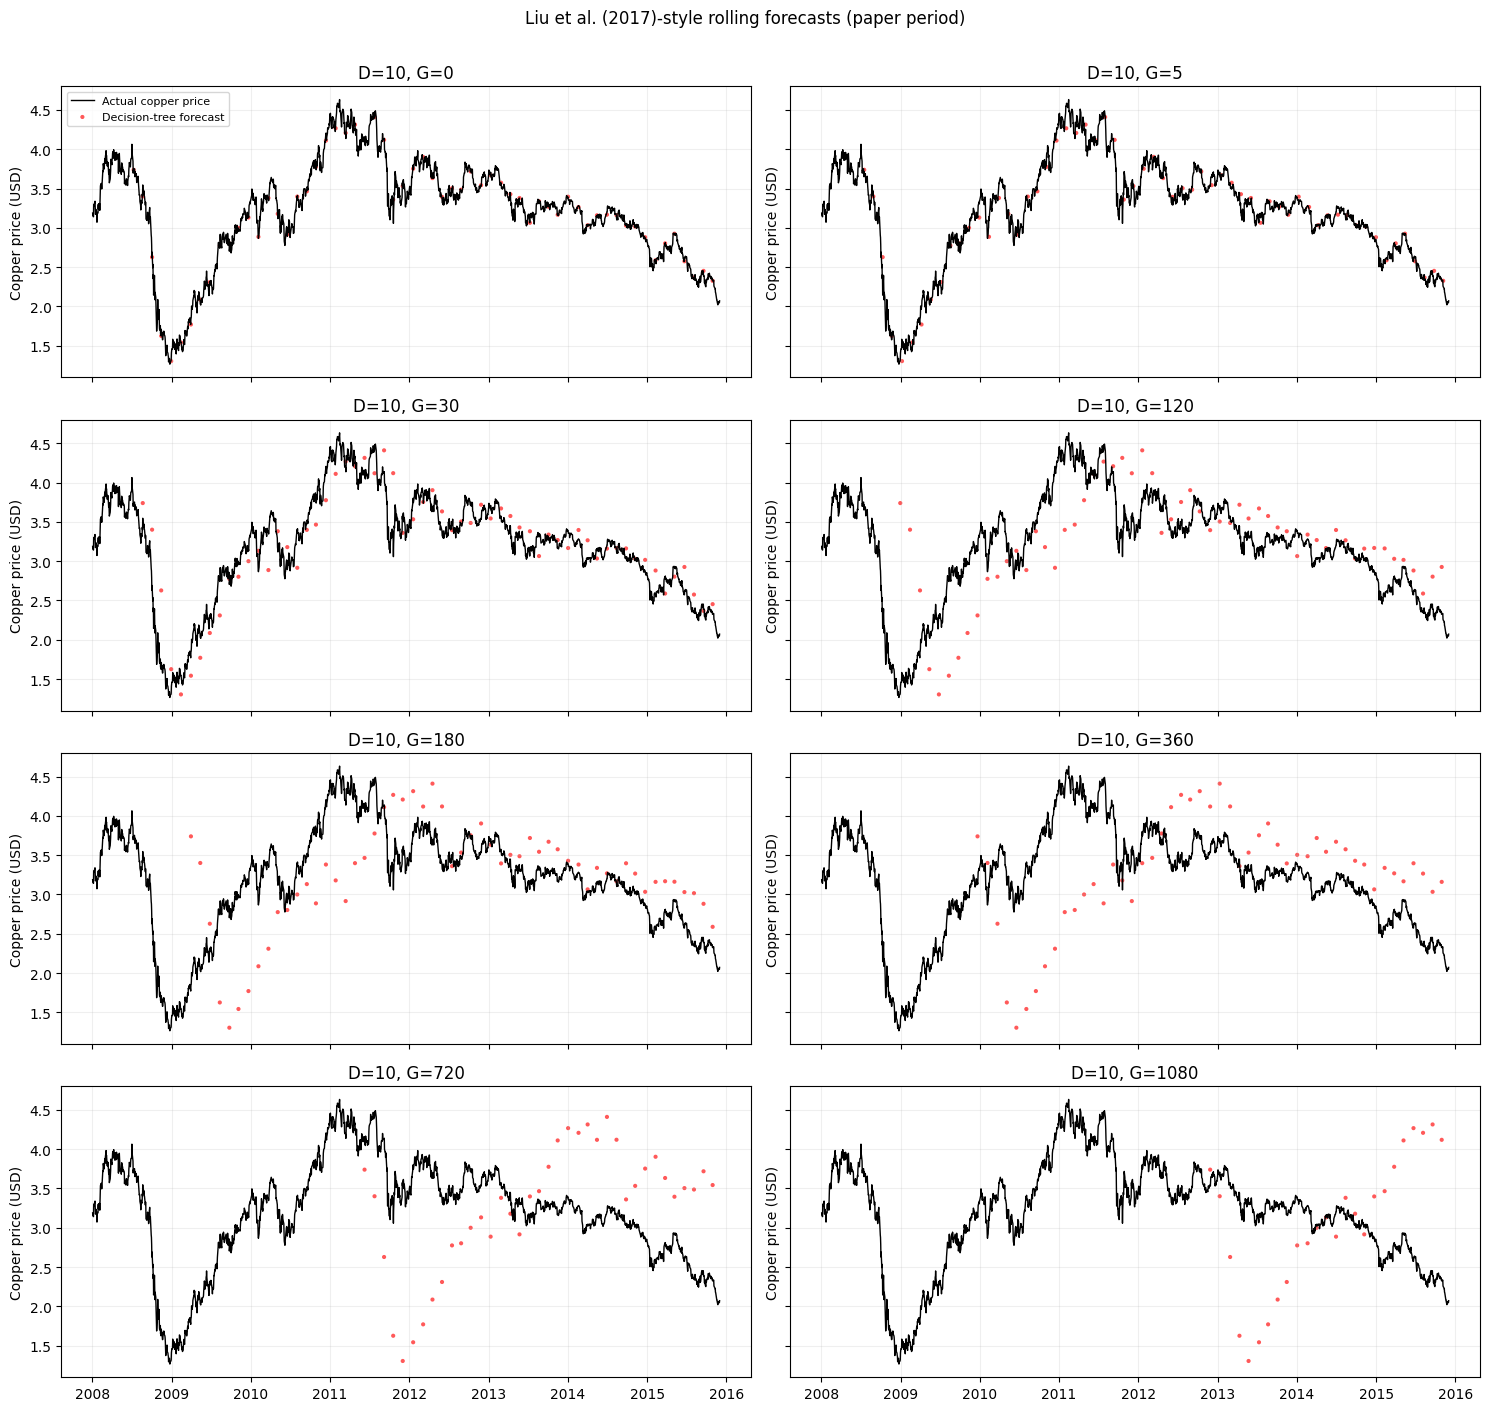

,D,G,Forecast distance (observations),N forecasts,MAE,RMSE,MAPE (%),Outliers >10% (%)
0,10,0,1,61,0.0303,0.0427,1.0284,0.0000
1,10,5,6,61,0.0843,0.1204,2.9271,4.9180
2,10,30,31,60,0.2298,0.2895,8.1353,21.6667
3,10,120,121,57,0.4555,0.6428,17.7268,45.6140
4,10,180,181,55,0.5315,0.6955,17.6468,63.6364
5,10,360,361,49,0.7361,0.8883,21.8128,81.6327
6,10,720,721,37,0.9467,1.0899,29.4682,86.4865
7,10,1080,1081,25,0.9307,1.1454,32.2613,68.0000


In [5]:
fig, axes = plt.subplots(4, 2, figsize=(15, 14), sharex=True, sharey=True)
for ax, G in zip(axes.ravel(), G_VALUES):
    ax.plot(paper_data.index, paper_data["Copper"], color="black", linewidth=1.0, label="Actual copper price")
    sub = liu_forecasts[liu_forecasts["G"] == G]
    if not sub.empty:
        ax.scatter(sub["TargetDate"], sub["Prediction"], color="red", s=9, alpha=0.65,
                   label="Decision-tree forecast", edgecolors="none")
    ax.set_title(f"D={D_PAPER}, G={G}")
    ax.set_ylabel("Copper price (USD)")
    ax.grid(alpha=0.2)
axes[0,0].legend(loc="upper left", fontsize=8)
fig.suptitle("Liu et al. (2017)-style rolling forecasts (paper period)", y=1.005)
fig.tight_layout()
fig.savefig(OUT / "figure8_style_liu_D10_various_G.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

# Error summaries for the rolling forecasts; errors are calculated only on generated predictions.
error_rows = []
for G, group in liu_forecasts.groupby("G"):
    actual = group["Actual"].to_numpy()
    pred = group["Prediction"].to_numpy()
    error_rows.append({
        "D": D_PAPER, "G": int(G), "Forecast distance (observations)": int(G+1),
        "N forecasts": len(group),
        "MAE": mean_absolute_error(actual, pred),
        "RMSE": mean_squared_error(actual, pred) ** 0.5,
        "MAPE (%)": np.mean(np.abs((actual-pred) / np.maximum(np.abs(actual), 1e-12))) * 100,
        "Outliers >10% (%)": np.mean(np.abs((pred-actual) / np.maximum(np.abs(actual), 1e-12)) > 0.10) * 100,
    })
liu_metrics = pd.DataFrame(error_rows).sort_values("G")
display(liu_metrics.round(4))
liu_metrics.to_csv(OUT / "liu2017_style_error_metrics.csv", index=False)

## 6. Modern model comparison: held-out 2008–2025 data

This second experiment is separate from the Liu-style rolling plot. It uses a chronological 80/20 split and a one-month-ahead target (21 common-date observations). Predictors use the latest `D` observations including today's observation. Training rows whose future target crosses the split date are excluded. The modern models use compact, explicit configurations so the notebook can run in a reasonable time.

In [6]:
HORIZONS = {"1 day": 1, "1 week": 5, "1 month": 21, "6 months": 126}
LAGS = [1, 5, 10, 20]
TUNE_D = 10
TUNE_H = HORIZONS["1 month"]
SPLIT_FRACTION = 0.80
split_pos = int(len(data) * SPLIT_FRACTION)
split_date = data.index[split_pos]
print("Chronological split date:", split_date.date())

def make_modern_supervised(frame, D, horizon):
    vals = frame[variables]
    X = pd.DataFrame(index=frame.index)
    # Most recent observation first in naming; includes the current forecast-origin observation.
    for lag in range(D):
        for col in variables:
            X[f"{col}_lag{lag}"] = vals[col].shift(lag)
    y = frame["Copper"].shift(-horizon).rename("target")
    joined = X.join(y).dropna()
    return joined.drop(columns="target"), joined["target"]

X_tune, y_tune = make_modern_supervised(data, TUNE_D, TUNE_H)
# Target must be no later than the split date for a training row to be valid.
position = pd.Series(np.arange(len(data)), index=data.index)
target_positions_tune = position.loc[X_tune.index].to_numpy() + TUNE_H
train_mask = (X_tune.index < split_date) & (target_positions_tune < split_pos)
test_mask = X_tune.index >= split_date
X_train_tune, y_train_tune = X_tune.loc[train_mask], y_tune.loc[train_mask]
X_test_tune, y_test_tune = X_tune.loc[test_mask], y_tune.loc[test_mask]
print(f"D={TUNE_D}, horizon={TUNE_H}; training rows={len(X_train_tune):,}; test rows={len(X_test_tune):,}")
if len(X_train_tune) < 100 or len(X_test_tune) < 20:
    raise ValueError("Not enough training/test rows. Check data coverage or reduce the horizon.")

Chronological split date: 2021-11-01
D=10, horizon=21; training rows=3,148; test rows=774


## 7. Configure models (lightweight, reproducible settings)

To keep the notebook reliable to run on a standard laptop, this version uses a small, explicit model configuration rather than an expensive large GridSearchCV. The Liu-style experiment above uses the paper-inspired decision tree. The modern comparison below tests several model families with fixed settings; you can expand tuning after the pipeline runs successfully.

In [7]:
models = {
    "RT": DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=RANDOM_STATE),
    "RF": RandomForestRegressor(n_estimators=50, max_depth=8, min_samples_leaf=3,
                                max_features=0.7, random_state=RANDOM_STATE, n_jobs=1),
    "GBM": GradientBoostingRegressor(n_estimators=75, max_depth=2, learning_rate=0.05,
                                     min_samples_leaf=3, random_state=RANDOM_STATE),
}
if HAS_XGBOOST:
    models["XGBoost"] = XGBRegressor(n_estimators=75, max_depth=3, learning_rate=0.05,
                                     subsample=0.8, objective="reg:squarederror",
                                     random_state=RANDOM_STATE, n_jobs=1, verbosity=0)

tuned_models = {name: clone(model) for name, model in models.items()}
tuning_table = pd.DataFrame([
    {"Model": name, "Configuration": str(model.get_params())}
    for name, model in tuned_models.items()
])
display(tuning_table)
tuning_table.to_csv(OUT / "table_model_configurations.csv", index=False)

,Model,Configuration
0,RT,"{'ccp_alpha': 0.0, 'criterion': 'squared_error..."
1,RF,"{'bootstrap': True, 'ccp_alpha': 0.0, 'criteri..."
2,GBM,"{'alpha': 0.9, 'ccp_alpha': 0.0, 'criterion': ..."
3,XGBoost,"{'objective': 'reg:squarederror', 'base_score'..."


## 8. Held-out model comparison and corrected random-walk benchmark

,Model,MAE,RMSE,R2,MAPE (%)
4,RW,0.2625,0.3533,0.4688,6.1706
2,GBM,0.2900,0.3954,0.3346,6.5999
3,XGBoost,0.2868,0.3970,0.3293,6.5260
1,RF,0.3355,0.4716,0.0534,7.8083
0,RT,0.4113,0.5486,-0.2808,9.8608


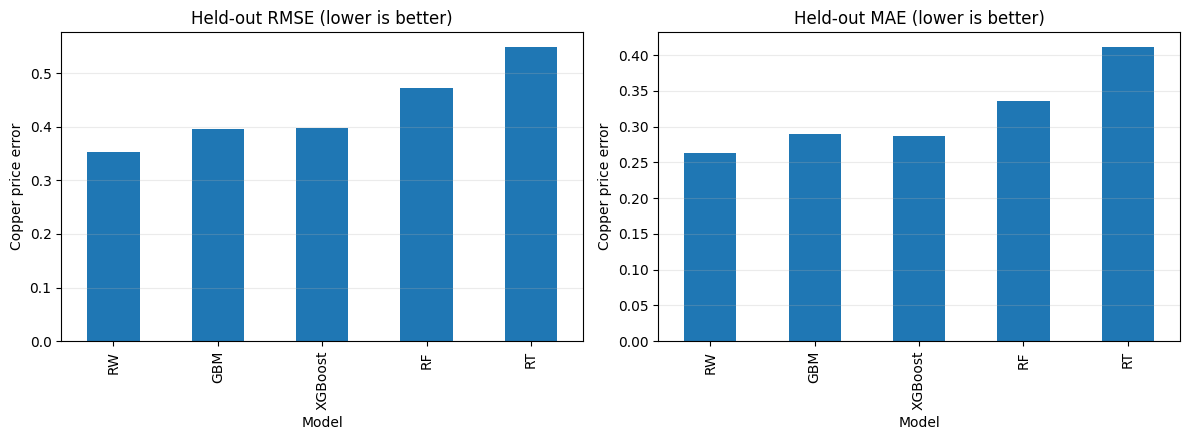

In [8]:
def metric_row(name, actual, pred):
    actual = np.asarray(actual, dtype=float)
    pred = np.asarray(pred, dtype=float)
    return {"Model": name,
            "MAE": mean_absolute_error(actual, pred),
            "RMSE": mean_squared_error(actual, pred) ** 0.5,
            "R2": r2_score(actual, pred),
            "MAPE (%)": np.mean(np.abs((actual-pred) / np.maximum(np.abs(actual), 1e-12))) * 100}

comparison_rows = []
predictions = {}
for name, base_model in tuned_models.items():
    model = clone(base_model)
    model.fit(X_train_tune, y_train_tune)
    pred = model.predict(X_test_tune)
    predictions[name] = pred
    comparison_rows.append(metric_row(name, y_test_tune, pred))
    tuned_models[name] = model

# Correct random walk: forecast future price using the price known at the forecast origin.
rw_pred = X_test_tune["Copper_lag0"].to_numpy()
predictions["RW"] = rw_pred
comparison_rows.append(metric_row("RW", y_test_tune, rw_pred))
model_comparison = pd.DataFrame(comparison_rows).sort_values("RMSE")
display(model_comparison.round(4))
model_comparison.to_csv(OUT / "table_model_comparison_test_metrics.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
model_comparison.set_index("Model")["RMSE"].plot(kind="bar", ax=axes[0], title="Held-out RMSE (lower is better)")
model_comparison.set_index("Model")["MAE"].plot(kind="bar", ax=axes[1], title="Held-out MAE (lower is better)")
for ax in axes:
    ax.set_ylabel("Copper price error")
    ax.grid(axis="y", alpha=.25)
fig.tight_layout()
fig.savefig(OUT / "figure4_model_comparison_metrics.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## 9. Compare models across lag lengths and horizons

,Model,MAE,RMSE,R2,MAPE (%),D,Horizon,Horizon steps
0,RT,0.1058,0.1914,0.8405,2.3227,1,1 day,1
1,RW,0.0557,0.0890,0.9655,1.3179,1,1 day,1
2,RT,0.2187,0.2952,0.6224,5.0482,1,1 week,5
3,RW,0.1328,0.1982,0.8298,3.1299,1,1 week,5
4,RT,0.3505,0.4475,0.1478,8.3194,1,1 month,21
5,RW,0.2625,0.3533,0.4688,6.1706,1,1 month,21
6,RT,0.6110,0.7491,-1.2166,14.6501,1,6 months,126
7,RW,0.4941,0.6100,-0.4700,11.9950,1,6 months,126
8,RT,0.1106,0.1953,0.8339,2.4383,5,1 day,1
9,RW,0.0557,0.0890,0.9655,1.3179,5,1 day,1


,D,Horizon,Model,MAE,RMSE,MAPE (%)
1,1,1 day,RW,0.0557,0.0890,1.3179
3,1,1 week,RW,0.1328,0.1982,3.1299
5,1,1 month,RW,0.2625,0.3533,6.1706
7,1,6 months,RW,0.4941,0.6100,11.9950
9,5,1 day,RW,0.0557,0.0890,1.3179
11,5,1 week,RW,0.1328,0.1982,3.1299
13,5,1 month,RW,0.2625,0.3533,6.1706
15,5,6 months,RW,0.4941,0.6100,11.9950
17,10,1 day,RW,0.0557,0.0890,1.3179
19,10,1 week,RW,0.1328,0.1982,3.1299


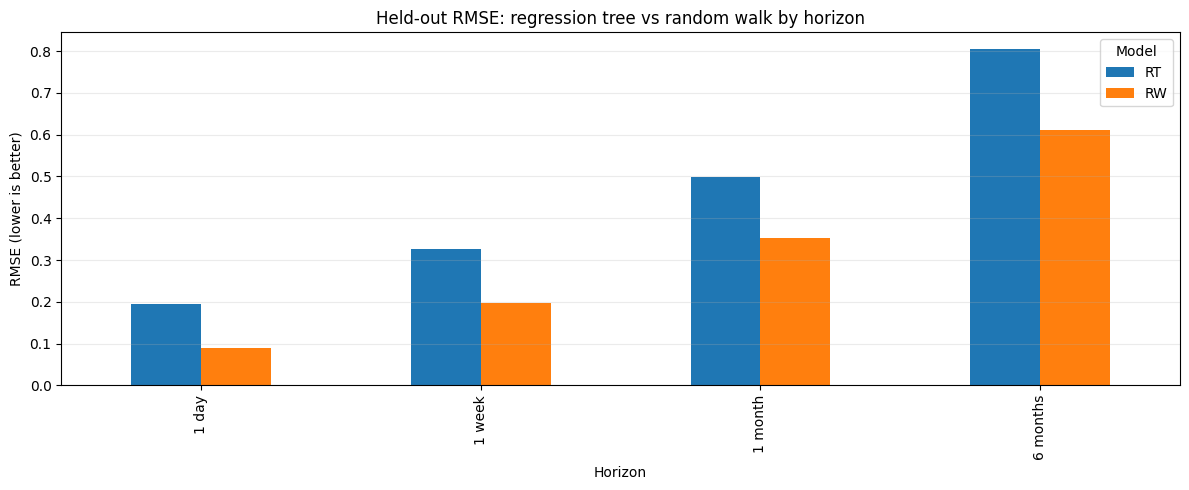

In [9]:
forecast_rows = []
# Keep the full D/horizon grid computationally light: evaluate the regression tree
# and random-walk benchmark at every setting. The full model-family comparison is
# already reported for D=10 and the one-month horizon in the preceding section.
for D in LAGS:
    for horizon_name, horizon in HORIZONS.items():
        X_all, y_all = make_modern_supervised(data, D, horizon)
        row_positions = position.loc[X_all.index].to_numpy()
        target_positions = row_positions + horizon
        tr_mask = (X_all.index < split_date) & (target_positions < split_pos)
        te_mask = X_all.index >= split_date
        Xtr, ytr = X_all.loc[tr_mask], y_all.loc[tr_mask]
        Xte, yte = X_all.loc[te_mask], y_all.loc[te_mask]
        if len(Xtr) < 100 or len(Xte) < 20:
            continue
        rt = DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=RANDOM_STATE)
        rt.fit(Xtr, ytr)
        row = metric_row("RT", yte, rt.predict(Xte))
        row.update({"D": D, "Horizon": horizon_name, "Horizon steps": horizon})
        forecast_rows.append(row)
        # For an H-step random-walk forecast, use price at origin t, not t-1.
        rw = Xte["Copper_lag0"].to_numpy()
        row = metric_row("RW", yte, rw)
        row.update({"D": D, "Horizon": horizon_name, "Horizon steps": horizon})
        forecast_rows.append(row)

forecast_results = pd.DataFrame(forecast_rows)
display(forecast_results.head(20).round(4))
forecast_results.to_csv(OUT / "table_forecast_metrics_all_models_lags_horizons.csv", index=False)
if not forecast_results.empty:
    best_idx = forecast_results.groupby(["D", "Horizon"])["RMSE"].idxmin()
    best_by_setting = forecast_results.loc[best_idx].sort_values(["D", "Horizon steps"])
    display(best_by_setting[["D", "Horizon", "Model", "MAE", "RMSE", "MAPE (%)"]].round(4))
    best_by_setting.to_csv(OUT / "table_best_model_by_lag_and_horizon.csv", index=False)
    pivot = forecast_results.groupby(["Horizon", "Model"])["RMSE"].mean().unstack()
    pivot = pivot.reindex(list(HORIZONS.keys()))
    ax = pivot.plot(kind="bar", figsize=(12, 5))
    ax.set_title("Held-out RMSE: regression tree vs random walk by horizon")
    ax.set_ylabel("RMSE (lower is better)")
    ax.grid(axis="y", alpha=.25)
    plt.tight_layout()
    plt.savefig(OUT / "figure5_rmse_by_horizon.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close()

## 10. Actual versus forecast (modern held-out test)

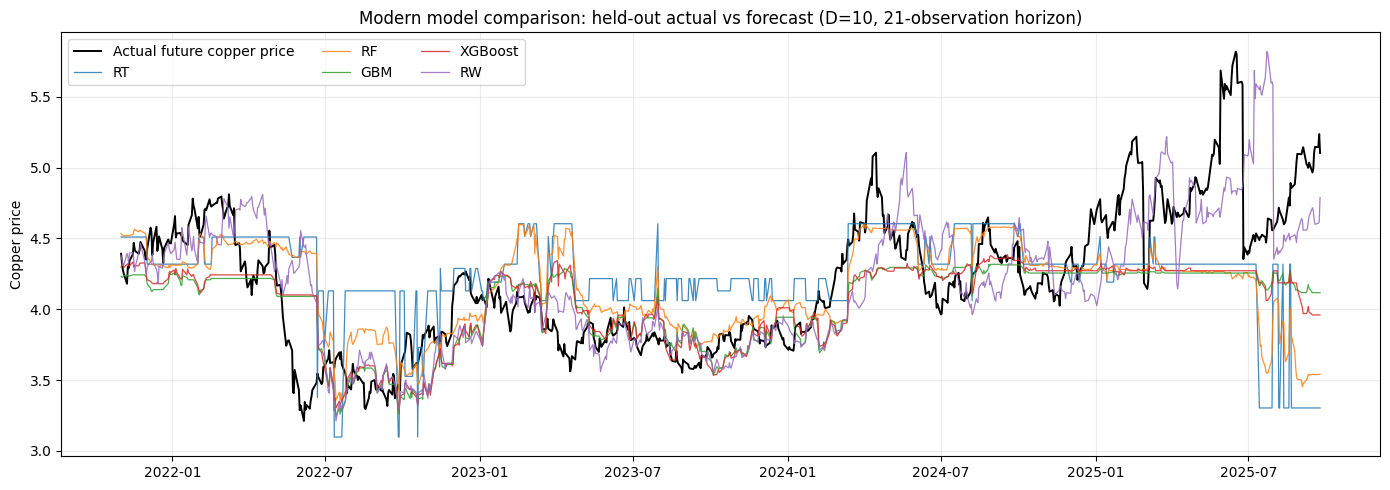

In [10]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y_test_tune.index, y_test_tune.values, label="Actual future copper price", linewidth=1.4, color="black")
for name, pred in predictions.items():
    ax.plot(y_test_tune.index, pred, label=name, linewidth=0.9, alpha=0.85)
ax.set_title("Modern model comparison: held-out actual vs forecast (D=10, 21-observation horizon)")
ax.set_ylabel("Copper price")
ax.legend(ncol=3)
ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(OUT / "figure6_actual_vs_forecasts_modern_test.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

## 11. Feature importance (dimension-safe)

Top 20 feature importances — RT


,Importance
Copper_lag0,0.882812
Gas_lag9,0.026894
Silver_lag7,0.012203
Dow Jones_lag0,0.008273
Silver_lag0,0.007341
Gold_lag9,0.007029
Coffee_lag9,0.005362
Oil_lag9,0.004787
Dow Jones_lag7,0.004404
Oil_lag8,0.003064


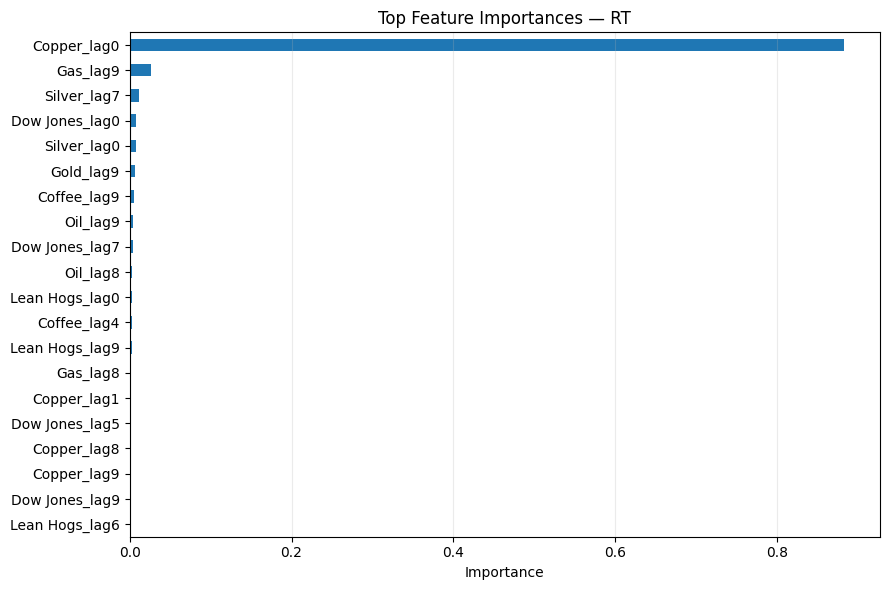

Top 20 feature importances — RF


,Importance
Copper_lag0,0.494732
Copper_lag1,0.230871
Copper_lag2,0.124166
Copper_lag5,0.013077
Gas_lag8,0.010062
Gas_lag9,0.009753
Copper_lag3,0.007303
Silver_lag0,0.004283
Copper_lag4,0.003943
Silver_lag1,0.003477


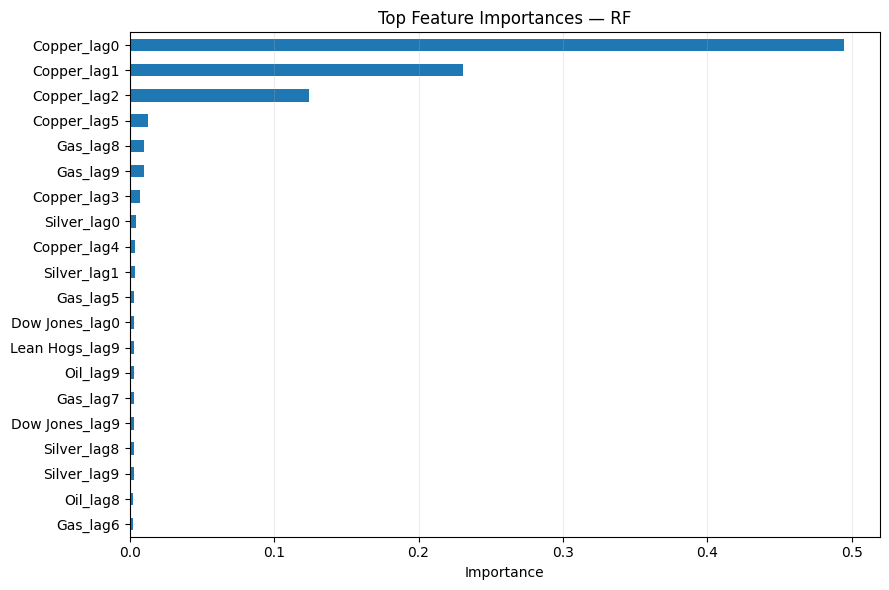

Top 20 feature importances — GBM


,Importance
Copper_lag0,0.745271
Copper_lag1,0.108044
Copper_lag2,0.034279
Gold_lag9,0.010322
Copper_lag3,0.008824
Silver_lag1,0.008264
Silver_lag2,0.007167
Copper_lag4,0.006819
Silver_lag3,0.006481
Gas_lag9,0.006464


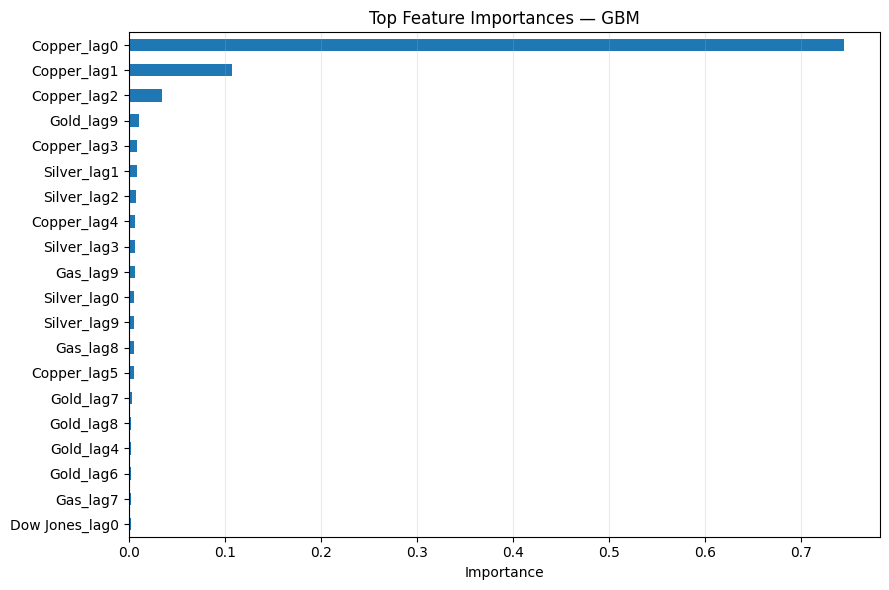

Top 20 feature importances — XGBoost


,Importance
Copper_lag0,0.155420
Copper_lag2,0.126435
Copper_lag1,0.112483
Copper_lag4,0.073922
Copper_lag3,0.057413
Copper_lag5,0.039984
Copper_lag7,0.022987
Silver_lag2,0.020515
Gas_lag8,0.015242
Gas_lag6,0.014265


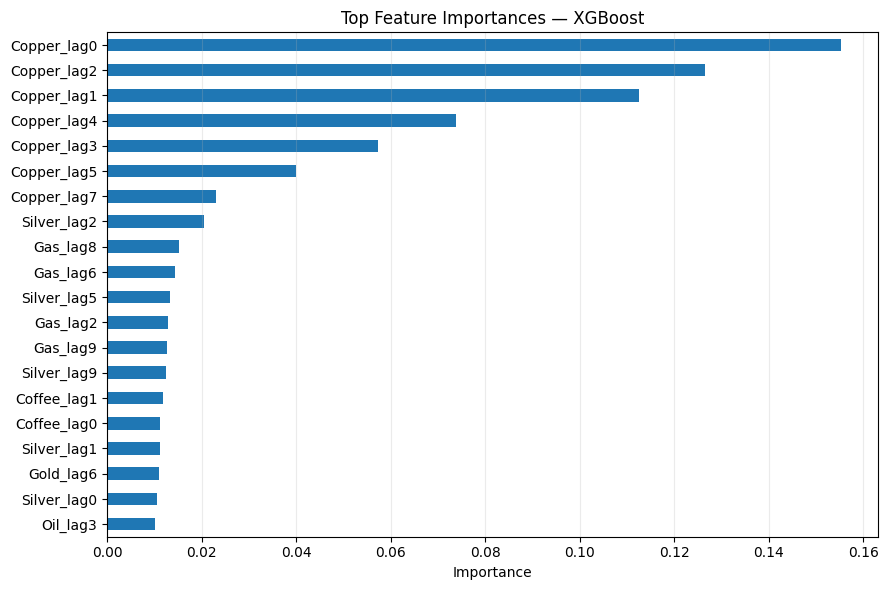

In [11]:
# Use each model's own fitted feature metadata. This avoids the old bug where a model
# fitted later on a different D (e.g., 80 lags = 640 features) was paired with the D=10 names.
for name, model in tuned_models.items():
    if not hasattr(model, "feature_importances_"):
        continue
    imp_values = np.asarray(model.feature_importances_).ravel()
    feature_names = list(getattr(model, "feature_names_in_", X_train_tune.columns))
    if len(imp_values) != len(feature_names):
        print(f"Skipping {name}: {len(imp_values)} importance values but {len(feature_names)} feature names.")
        continue
    imp = pd.Series(imp_values, index=feature_names).sort_values(ascending=False).head(20)
    print(f"Top 20 feature importances — {name}")
    display(imp.to_frame("Importance"))
    imp.to_csv(OUT / f"feature_importance_{name}.csv")
    fig, ax = plt.subplots(figsize=(9, 6))
    imp.sort_values().plot(kind="barh", ax=ax)
    ax.set_title(f"Top Feature Importances — {name}")
    ax.set_xlabel("Importance")
    ax.grid(axis="x", alpha=.25)
    fig.tight_layout()
    fig.savefig(OUT / f"figure7_feature_importance_{name}.png", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## 12. Output summary and interpretation notes

Outputs are saved in `copper_forecasting_outputs/`, including:

- `figure8_style_liu_D10_various_G.png`: the paper-inspired eight-panel plot.
- `liu2017_style_rolling_forecasts_D10.csv`: all generated rolling-origin forecasts.
- `liu2017_style_error_metrics.csv`: MAE, RMSE, MAPE, and >10% error share by `G`.
- `table_model_comparison_test_metrics.csv`: held-out modern model comparison.
- `table_forecast_metrics_all_models_lags_horizons.csv`: performance across lag/horizon settings.
- `figure6_actual_vs_forecasts_modern_test.png`: actual vs forecast for the modern held-out experiment.

### How to interpret the replication

The paper's red dots are predictions made from many different forecast origins, not one static forecast line. This notebook plots each prediction at the **target date** it forecasts, which makes it comparable in style to the paper. The target is always `G+1` common-date observations after the origin. `G=0` means the next available row in the aligned dataset.

The paper's preprocessing filled missing holiday values by averaging neighboring values, whereas this notebook uses the intersection of dates shared by all eight downloaded CSVs. The paper's original data may also differ from current Investing.com historical data. Therefore, numerical agreement is not guaranteed. Do not compare error metrics unless the date alignment and evaluation protocol are also matched.

### Reproducibility checks

- Training targets are restricted to observations available at each rolling forecast origin.
- The modern held-out training split excludes training examples whose future targets cross the split date.
- The random-walk baseline uses the price at the forecast origin (`Copper_lag0`).
- Feature importance uses the feature names belonging to the fitted model, avoiding the earlier 640-vs-80 length error.
- XGBoost is optional; absence of the package does not stop the notebook.